In [122]:
import pandas as pd 
import sys
print(sys.executable)
import kagglehub
import os
from pyexpat import model
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score,roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import yaml
from pathlib import Path
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from random import shuffle
from sklearn.utils import shuffle
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, precision_score, recall_score
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.datasets import make_classification
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report
from xgboost import XGBClassifier

/opt/anaconda3/envs/py311/bin/python


In [123]:
def load_data(path):
    files = os.listdir(path)
    df = pd.read_csv(os.path.join(path, files[0]))
    return df
df = load_data("/Users/enkhjin/.cache/kagglehub/datasets/saurabhbadole/bank-customer-churn-prediction-dataset/versions/2")
print(df.head())  

   RowNumber  CustomerId   Surname  ...  IsActiveMember EstimatedSalary Exited
0          1    15634602  Hargrave  ...               1       101348.88      1
1          2    15647311      Hill  ...               1       112542.58      0
2          3    15619304      Onio  ...               0       113931.57      1
3          4    15701354      Boni  ...               0        93826.63      0
4          5    15737888  Mitchell  ...               1        79084.10      0

[5 rows x 14 columns]


In [124]:
def load_config(path=None):
    if path is not None:
        config_path = Path(path)
        if not config_path.is_file():
            raise FileNotFoundError(f"Configuration file not found: {config_path}")
    else:
        config_candidates = (
            Path("configs.yaml"),
            Path("../configs.yaml"),
            Path("config/configs.yaml"),
            Path("../config/configs.yaml"),
        )
        config_path = next((candidate for candidate in config_candidates if candidate.is_file()), None)
        if config_path is None:
            searched = ", ".join(str(candidate) for candidate in config_candidates)
            raise FileNotFoundError(f"Could not find configs.yaml; searched: {searched}")

    with config_path.open("r", encoding="utf-8") as config_file:
        return yaml.safe_load(config_file)
if __name__ == "main":
    config = load_config()
    print(config)

In [125]:
def check_missing_duplicated_values(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None, None
    missing_values = df.isnull().any()
    duplicated_rows = df.duplicated().any()
    check = missing_values.sum() or duplicated_rows.sum()
    if missing_values.sum() > 0:
        print("There are missing values in the DataFrame.")
    if duplicated_rows.sum() > 0:
        print("There are duplicated rows in the DataFrame.")
    return check
if __name__ == "__main__":
    print(check_missing_duplicated_values(df))
    

0


In [126]:
def number_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return 0
    numeric_columns = df.select_dtypes(include=['number']).shape[1]
    return numeric_columns
if __name__ == "__main__":
    print("Number of numeric columns:", number_columns(df))

Number of numeric columns: 11


In [127]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [128]:
('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

('line',
 'bar',
 'barh',
 'kde',
 'density',
 'area',
 'hist',
 'box',
 'pie',
 'scatter',
 'hexbin')

NumOfProducts  IsActiveMember
1              0                 924
               1                 485
2              0                 212
               1                 136
3              0                 135
dtype: int64


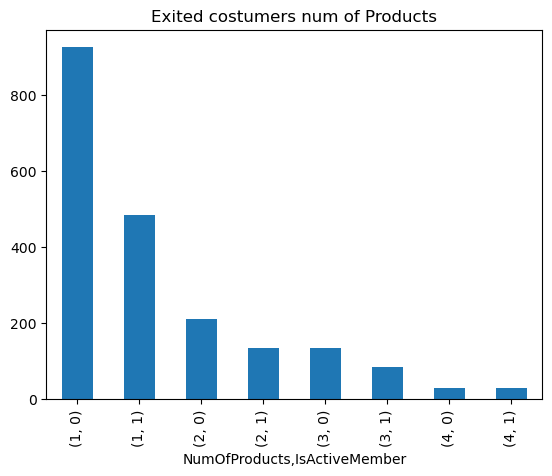

In [129]:
exited = df[df['Exited'] == 1]
value_counts = exited.groupby(['NumOfProducts','IsActiveMember']).size()
# value_counts = df.groupby('Exited').count()

print(value_counts.head())
value_counts.plot(kind='bar',x='Products', y='exited',
                  title='Exited costumers num of Products')
plt.show()

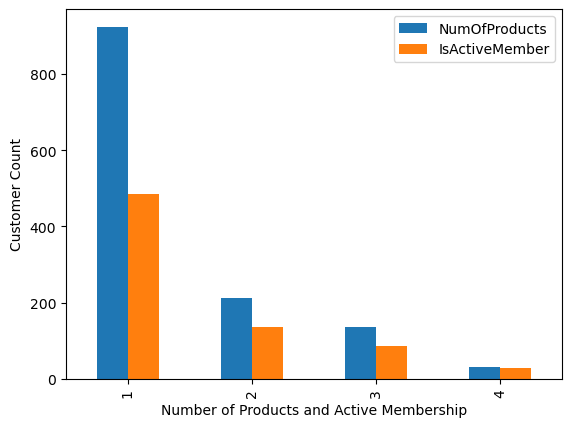

In [130]:
exited = df[df['Exited'] == 1]
value_counts = pd.crosstab(
    exited['NumOfProducts'], exited['IsActiveMember']
)

value_counts.plot(kind='bar')
plt.xlabel('Number of Products and Active Membership')
plt.ylabel('Customer Count')
plt.legend(['NumOfProducts', 'IsActiveMember'])
plt.show()

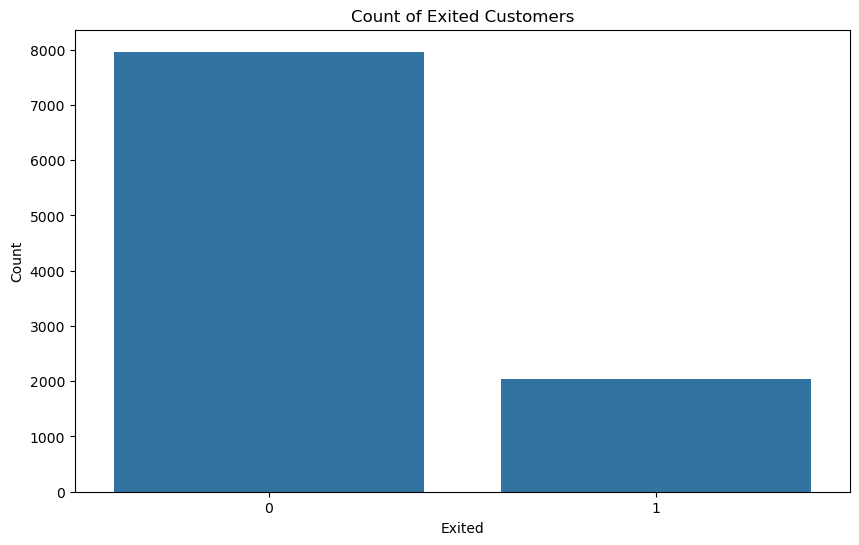

None


In [131]:
def plot(df):
    plt.figure(figsize=(10, 6))
    sns.countplot(x='Exited', data=df)
    plt.title('Count of Exited Customers')
    plt.xlabel('Exited')
    plt.ylabel('Count')
    plt.show()
if __name__ == "__main__":
    print(plot(df))


 We plotted the exited costumers to check the class imbalance, and adjust later on our upsampling strategy. 

In [132]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [133]:

print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [134]:
def drop_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return df
    return df.drop(columns=['Surname', 'RowNumber', 'CustomerId'])

df_drop = drop_columns(df)
print(df_drop.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [135]:
def encoding_columns(df):
    if df.empty:
        print("The DataFrame is empty.")
        return df
    categorical_columns = df.select_dtypes(include=['object']).columns
    print("Categorical columns to encode:", categorical_columns)
    df_encoded = pd.get_dummies(df, drop_first=True,
                                columns = categorical_columns,
                                dtype=int)
    return df_encoded
df_encoded = encoding_columns(df_drop)
print(df_encoded.head())

Categorical columns to encode: Index(['Geography', 'Gender'], dtype='object')
   CreditScore  Age  Tenure  ...  Geography_Germany  Geography_Spain  Gender_Male
0          619   42       2  ...                  0                0            0
1          608   41       1  ...                  0                1            0
2          502   42       8  ...                  0                0            0
3          699   39       1  ...                  0                0            0
4          850   43       2  ...                  0                1            0

[5 rows x 12 columns]


In [136]:
df_encoded.head()
df_exited = df_encoded[df_encoded['Exited'] == 1]
df_exited.value_counts()

CreditScore  Age  Tenure  Balance    NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  Geography_Germany  Geography_Spain  Gender_Male
350          39   0       109733.20  2              0          0               123602.11        1       1                  0                1              1
691          58   3       0.00       1              0          1               194930.30        1       0                  0                1              1
693          36   8       178111.82  1              0          0               58719.63         1       0                  0                1              1
             35   5       124151.09  1              1          0               88705.14         1       0                  0                0              1
692          47   3       0.00       2              1          0               150802.41        1       0                  1                0              1
                                                               

Age                  0.285323
Geography_Germany    0.173488
Balance              0.118533
EstimatedSalary      0.012097
HasCrCard           -0.007138
Tenure              -0.014001
CreditScore         -0.027094
NumOfProducts       -0.047820
Geography_Spain     -0.052667
Gender_Male         -0.106512
IsActiveMember      -0.156128
Name: Exited, dtype: float64


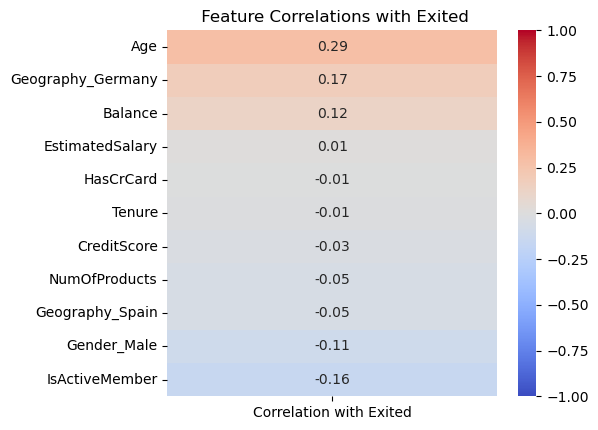

In [137]:
def corr_target(df):
    if df.empty:
        print("The DataFrame is empty.")
        return None
    correlation_matrixxx = df.corr()['Exited']
    correlation_matrix = correlation_matrixxx.drop("Exited").sort_values(ascending=False)
    return correlation_matrix
corr = corr_target(df_encoded)
print(corr)
# corr.plot(kind='bar', x=corr.index, 
#         y=corr.values,
#         title='Correlation with Target Variable (Exited)',
#         xlabel='Features', ylabel='Correlation Coefficient')
# plt.show()
plt.figure(figsize=(6, max(4, len(corr) * 0.4)))
sns.heatmap(
    corr.to_frame(name="Correlation with Exited"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title(" Feature Correlations with Exited")
plt.tight_layout()
plt.show()

In [138]:
def splitting_data(df):
    if df.empty:
        print("Dataframe is empty.")
        return None
    config = load_config()
    target = df['Exited']
    features = df.drop(columns=['Exited'], axis=1)
    x_temp,x_test, y_temp,y_test = train_test_split(features, target,
                                                    test_size=0.25, 
                                                    random_state=42,
                                                    stratify=target)
    x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp,
                                                      test_size=0.25, 
                                                      random_state=42,
                                                      stratify=y_temp)
    return x_train, x_val, x_test, y_train, y_val, y_test  
x_train, x_val, x_test, y_train, y_val, y_test = splitting_data(df_encoded)
print(f"Training set: {x_train.shape[0]} samples")
print(f"Validation set: {x_val.shape[0]} samples")


Training set: 5625 samples
Validation set: 1875 samples


In [139]:
def tuning_hyperparameters_rf(x_train, y_train, x_val, y_val):
    param_grid = {
        'n_estimators': [20, 50,100, 150, 200, 300],
        'max_depth': [5, 10, 20, 30, 8],
        'min_samples_split': [2, 5, 10, 15, 8],
        'bootstrap': [True, False],
        'class_weight': ['balanced_subsample', 'balanced'],
        }
  
    rf = RandomForestClassifier(random_state=42)
    
    random_search = RandomizedSearchCV(
            param_distributions=param_grid,
            scoring='f1',
            cv=3,
            n_jobs=-1,
            estimator= rf,
            verbose=1
            )
    random_search.fit(x_train, y_train)
    best_model = random_search.best_estimator_
    best_params = random_search.best_params_
    best_f1 = random_search.best_score_
    
    prediction = random_search.predict(x_val)
    precision = precision_score(y_val, prediction)
    recall = recall_score(y_val, prediction)
    return best_model, best_params, best_f1, precision, recall
                        
best_model_fr, best_params_rf, best_f1_rf, precision_rf, precision_rf = tuning_hyperparameters_rf(x_train, y_train, x_val, y_val)
print("=== Best Results ===")
print(best_model_fr)
print(f"Best f1 score:", best_f1_rf)
print(precision_rf, precision_rf)
                            

Fitting 3 folds for each of 10 candidates, totalling 30 fits


=== Best Results ===
RandomForestClassifier(bootstrap=False, class_weight='balanced_subsample',
                       max_depth=8, n_estimators=200, random_state=42)
Best f1 score: 0.5945096247054152
0.7198952879581152 0.7198952879581152


In [140]:
def tuning_hyperparameters(x_train, y_train, x_val, y_val):

    param_grid = {
        'n_estimators': [50, 100, 150],
        'max_depth': [2, 3, 5],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 5],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.8, 1.0],
        'max_features': ['sqrt', 'log2', None],
        'loss': ['log_loss', 'exponential']
    }

    model = GradientBoostingClassifier(random_state=42)

    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=30,             # Test only 30 combinations
        scoring='f1',
        cv=3,                  # 3-fold cross-validation
        random_state=42,
        n_jobs=-1,              # Use available CPU cores
        verbose=1
    )

    random_search.fit(x_train, y_train)

    best_model = random_search.best_estimator_

    # Evaluate the best model on the validation set
    prediction = best_model.predict(x_val)

    best_f1 = f1_score(y_val, prediction, zero_division=0)
    precision = precision_score(y_val, prediction, zero_division=0)
    recall = recall_score(y_val, prediction, zero_division=0)

    best_params = random_search.best_params_

    return best_model, best_params, best_f1, precision, recall


best_model_gb, best_params_gb, best_f1_gb, precision_gb, recall_gb = tuning_hyperparameters( x_train, y_train, x_val, y_val)
print("=== Best Results ===")
print("Best model:", best_model_gb)
print("Best parameters:", best_params_gb)
print("Validation F1:", best_f1_gb)
print("Validation precision:", precision_gb)
print("Validation recall:", recall_gb)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
=== Best Results ===
Best model: GradientBoostingClassifier(max_depth=5, min_samples_split=10, n_estimators=50,
                           random_state=42)
Best parameters: {'subsample': 1.0, 'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 5, 'loss': 'log_loss', 'learning_rate': 0.1}
Validation F1: 0.5949367088607594
Validation precision: 0.752
Validation recall: 0.49214659685863876


In [141]:
def tuning_hyperparameter_lr(x_train, y_train, x_val, y_val):
    best_f1 = 0
    best_model = None
    best_params = {}
    param_grid = {
        'max_iter' : [100, 150, 200],
        'C' : [0.01, 0.1, 1, 10]}
    
    for max_iter in param_grid['max_iter']:
        for C in param_grid['C']:
            model = LogisticRegression(random_state=42,
                            class_weight = 'balanced',
                            max_iter = max_iter,
                            C = C )
            model.fit(x_train, y_train)
            prediction = model.predict(x_val)
            f1 = f1_score(y_val, prediction)
            precision = precision_score(y_val, prediction)
            recall = recall_score(y_val, prediction)
            if f1 > best_f1:
                best_f1 = f1
                best_model = model
                best_params = {
                    'max_iter' : max_iter,
                    'C' : C         }
                # print(f"New best model found: F1 = {best_f1}, Params = {best_params},, precision = {precision}, recall = {recall})")
    return best_model, best_f1, best_params
best_model_lr, best_f1_lr, best_params_lr = tuning_hyperparameter_lr(x_train, y_train, x_val, y_val)
print("=== Best Results of Logistic Regression ===")
print(f"Best F1-Score: {best_f1_lr:.4f}")
print(f"Best Parameters: {best_params_lr}")                    


=== Best Results of Logistic Regression ===
Best F1-Score: 0.4622
Best Parameters: {'max_iter': 150, 'C': 0.01}


In [149]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scl', StandardScaler())]), selector(dtype_include=np.number)),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), selector(dtype_include=object))
    ])
# full_pipeline = Pipeline(steps=[
#     ('preprocessing', preprocessor),
#     ('classifier', param_grid)])
param_grid ={
      "Logistic Regression": {
        'classifier': [LogisticRegression(solver='liblinear', random_state=42)],
        'classifier__C': [0.01, 0.1, 1.0, 10.0],
        'classifier__penalty': ['l1', 'l2'], 
        'classifier__max_iter': [150, 200, 300]
    },
     "Random Forest":{
        'classifier': [RandomForestClassifier(random_state=42)],
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [5, 10, None],
        'classifier__class_weight': ['balanced', 'balanced_subsample']
    },
   "Gradient Boosting": {
        'classifier': [GradientBoostingClassifier(loss='log_loss', random_state=42)],
        'classifier__n_estimators': [50, 100],
        'classifier__learning_rate': [0.05, 0.1, 0.2],
        'classifier__max_depth': [3, 5, 7]
    }}
searches = {}
results = []
for name,grid in param_grid.items():
    search = GridSearchCV(
        estimator=full_pipeline,
        param_grid=grid, 
        cv=5,
        scoring='f1',
        n_jobs=-1,
        refit=True)
    search.fit(x_train, y_train)
    prediction = search.predict(x_val)
    searches[name] = search
    # best_f1 = search.best_score_
    # precision = precision_score(y_val, prediction)
    probability = search.predict_proba(x_val)[:, 1]

    # recall = recall_score(y_val, prediction)
    results.append({
        "Model": name,
        "CV F1": search.best_score_,
        "Validation F1": f1_score(y_val, prediction),
        "Accuracy": accuracy_score(y_val, prediction),
        "Precision": precision_score(y_val, prediction),
        "Recall": recall_score(y_val, prediction),
        "ROC AUC": roc_auc_score(y_val, probability)})
results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))
print("Starting cross-validated tuning over Logistic Regression, Random Forest, and GB...")
print(f"\n🥇 Winning Architecture Details:\n{search.best_params_['classifier']}")
print(f" Best Validation Score: {search.best_score_:.2%}")

# Evaluate the optimized selected pipeline directly against the holdout set
val_set_f1 = f1_score(y_val, prediction)
val_set_accuracy = accuracy_score(y_val, prediction)

print(f" Validation set f1 score: {val_set_f1:.2%}")


,CV F1,Validation F1,Accuracy,Precision,Recall,ROC AUC
Model,,,,,,
Logistic Regression,0.312,0.328,0.808,0.571,0.230,0.751
Random Forest,0.598,0.642,0.855,0.646,0.639,0.858
Gradient Boosting,0.574,0.618,0.867,0.743,0.529,0.862


Starting cross-validated tuning over Logistic Regression, Random Forest, and GB...

🥇 Winning Architecture Details:
GradientBoostingClassifier(random_state=42)
 Best Validation Score: 57.44%
 Validation set f1 score: 61.77%


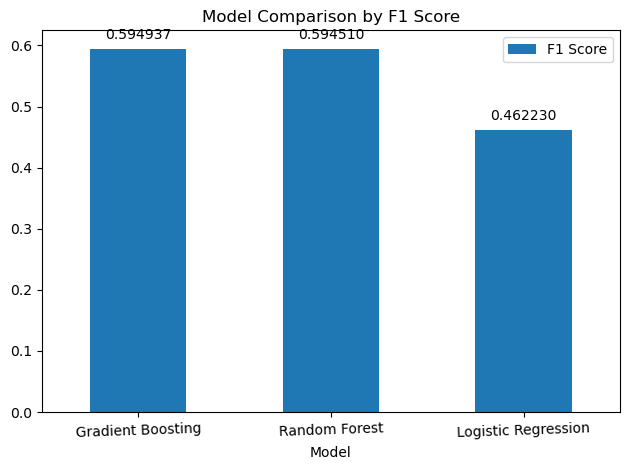

In [143]:
compare_models = pd.DataFrame({'Model':['Random Forest', 'Logistic Regression', 'Gradient Boosting'],
                               'F1 Score':[best_f1_rf,best_f1_lr,best_f1_gb]})
compare_models.sort_values(by='F1 Score', ascending=False, inplace=True)
comp_models = compare_models.plot(kind='bar', x='Model', y='F1 Score', title='Model Comparison by F1 Score')    
for bars in comp_models.containers:
    comp_models.bar_label(bars, fmt="%.6f", padding=5)
plt.xticks(rotation=2)
plt.tight_layout()
plt.show()

In [144]:
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]
    features_upsample = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsample = pd.concat([target_zeros] + [target_ones] * repeat)
    features_upsample, target_upsample = shuffle(features_upsample, target_upsample)
    return features_upsample, target_upsample
config = load_config()
features_upsample, target_upsample = upsample(x_train, y_train, 4)

In [145]:
def model_training_rf(y_train,x_train, x_val, y_val):
    upsample_model = RandomForestClassifier(random_state=config['rf_model']['random_state'],
                                                    n_estimators= config['rf_model']['n_estimators'],
                                                    max_depth= config['rf_model']['max_depth'],
                                                    min_samples_split= config['rf_model']['min_samples_split'],
                                                    bootstrap=config['rf_model']['bootstrap'],
                                                    # class_weight =config['rf_model']['class_weight']
                                                    )
    upsample_model.fit(y_train,x_train)
    prediction = upsample_model.predict(x_val)
    precision = precision_score(y_val, prediction)
    f1 = f1_score(y_val, prediction)
    return prediction, precision, f1, upsample_model
prediction_upsample, precision_upsample, f1_upsample, upsample_model = model_training_rf(features_upsample, target_upsample,x_val, y_val)
print("Best model with upsampling:", upsample_model)
print("Best f1 with upsampling:", f1_upsample)

Best model with upsampling: RandomForestClassifier(max_depth=5, min_samples_split=15, n_estimators=200,
                       random_state=42)
Best f1 with upsampling: 0.5832471561530507


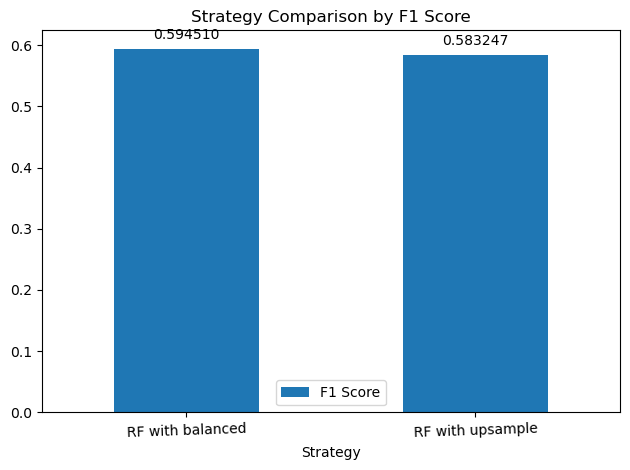

In [146]:
compare_strategy = pd.DataFrame({'Strategy':['RF with balanced', 'RF with upsample'],
                               'F1 Score':[best_f1_rf,f1_upsample]})
compare_strategy.sort_values(by='F1 Score', ascending=False, inplace=True)
comp_strat = compare_strategy.plot(kind='bar', x='Strategy', y='F1 Score', title='Strategy Comparison by F1 Score')    
for bars in comp_strat.containers:
    comp_strat.bar_label(bars, fmt="%.6f", padding=5)
plt.xticks(rotation=2)
plt.tight_layout()
plt.show()

The plot indicated the Random Forest model with balanced strategy shows the best f1 result. (0.59)

In [147]:
prediction_test, precision_test, f1_test, model_test= model_training_rf(x_train, y_train, x_test, y_test )
print("===================")
print( "The best model:", model_test)
print("The best f1 score on the best model:", f1_test)

The best model: RandomForestClassifier(max_depth=5, min_samples_split=15, n_estimators=200,
                       random_state=42)
The best f1 score on the best model: 0.504225352112676


Conclusion
The dataset contains 10,000 rows and 14 columns. The objective was to predict whether a bank customer would remain with the bank or leave, using the Exited column as the target variable.

The RowNumber, CustomerId, and Surname columns were removed because they do not provide useful predictive information. Logistic Regression, Gradient Boosting, and Random Forest models were trained and evaluated on the validation set.

Among the initial models, Random Forest achieved the highest F1 score. Because the target variable is imbalanced, class weighting and minority-class upsampling were also evaluated. The class-weighted Random Forest achieved the best validation performance, with an F1 score of approximately 0.59.

This model was then evaluated on the held-out test set, where it achieved an F1 score of approximately 0.50.

Recommendation


Collecting a larger and more representative dataset—particularly one containing more examples of customers who leave the bank—could help the model identify churn patterns more effectively and improve predictive performance. Any future improvements should be evaluated using a separate, unseen test set.